In [1]:

# Cell 1: Import libraries and load the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Display the first five rows
display(df.head())

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Statistical summary
display(df.describe(include='all'))


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing values:
cus

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,3186-AJIEK,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [2]:

# CELL 2: DATA CLEANING AND PREPROCESSING

# Create a copy of the original dataset
df_clean = df.copy()

# 1. Check duplicate records
print("Duplicate rows:", df_clean.duplicated().sum())

# 2. Remove duplicate records if any
df_clean = df_clean.drop_duplicates()

# 3. Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"], errors="coerce"
)

# 4. Check missing values after conversion
print("\nMissing values after conversion:")
print(df_clean.isnull().sum())

# 5. Fill missing TotalCharges values with the median
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(
    df_clean["TotalCharges"].median()
)

# 6. Check dataset information
print("\nCleaned dataset information:")
df_clean.info()

# 7. Verify the cleaned dataset
print("\nFinal dataset shape:", df_clean.shape)
print("\nTotal missing values:", df_clean.isnull().sum().sum())

display(df_clean.head())


Duplicate rows: 0

Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Cleaned dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-n

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


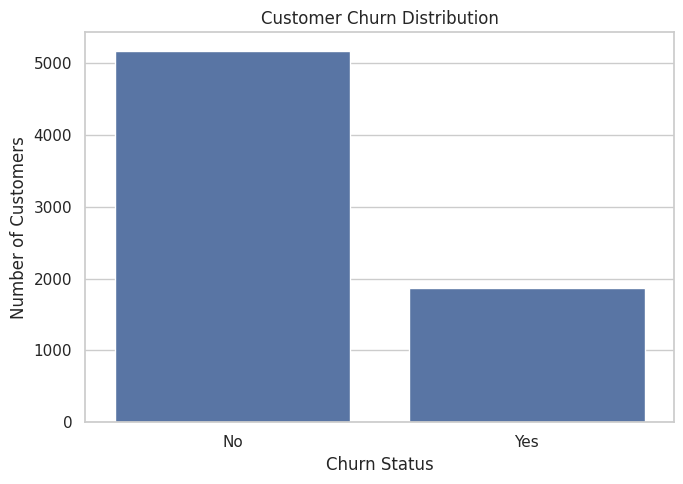

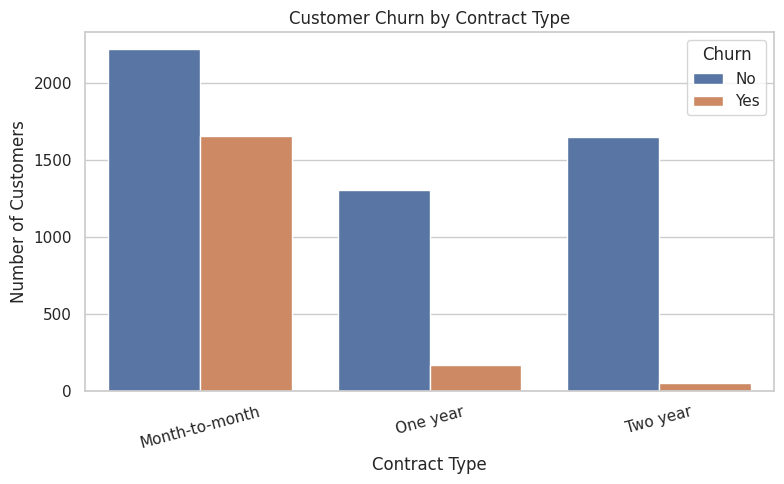

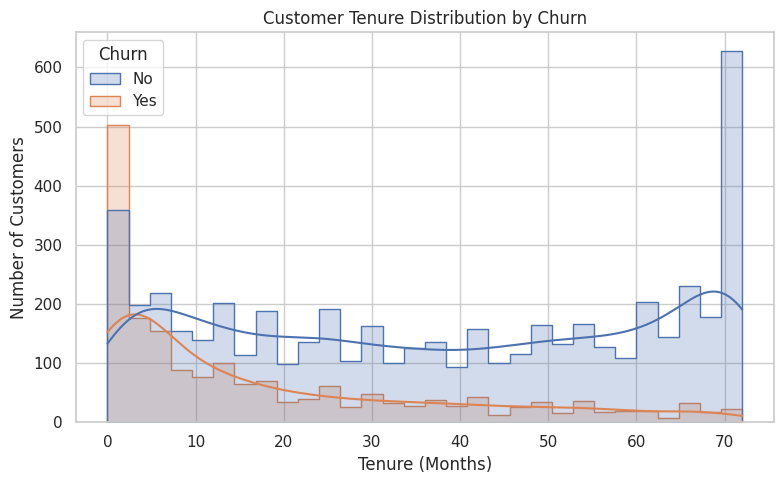

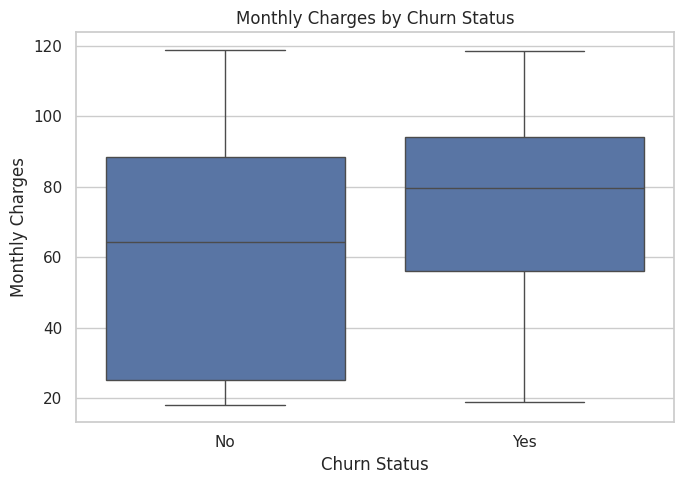

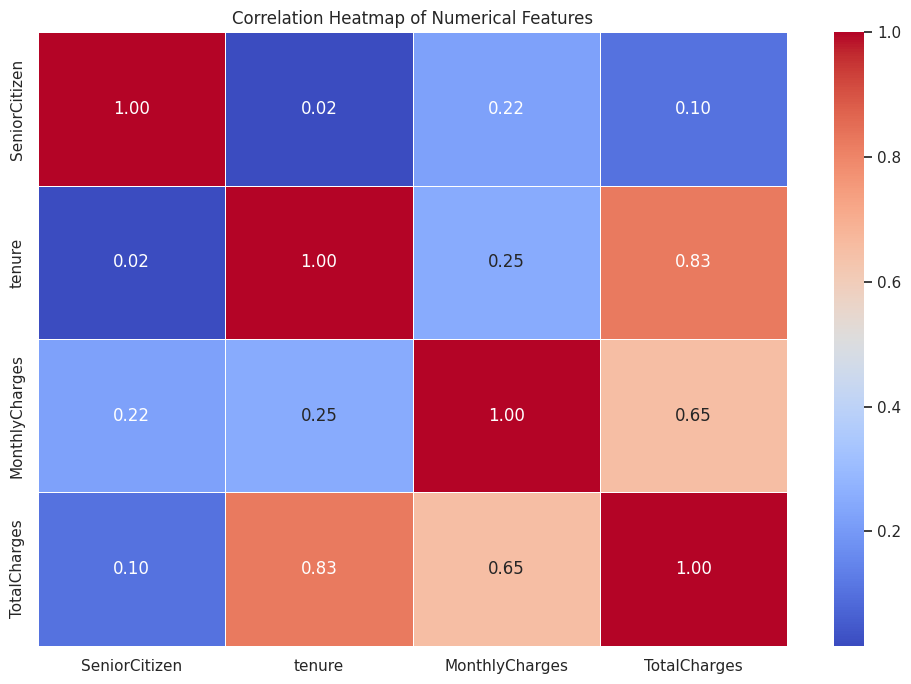

In [3]:

# CELL 3: EXPLORATORY DATA ANALYSIS

# Set visualization style
sns.set_theme(style="whitegrid")

# 1. Customer Churn Distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# 2. Churn by Contract Type
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x="Contract", hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 3. Customer Tenure Distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="tenure", hue="Churn",
             bins=30, kde=True, element="step")
plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# 4. Monthly Charges by Churn Status
plt.figure(figsize=(7, 5))
sns.boxplot(data=df_clean, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

# 5. Correlation Heatmap
numeric_df = df_clean.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm",
            fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


In [6]:

# CELL 4: DATA PREPARATION FOR ANN

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Start from the cleaned dataset
model_df = df_clean.copy()

# Remove customer identifier
model_df = model_df.drop(columns=["customerID"])

# Convert target into binary values
model_df["Churn"] = model_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Encode categorical features
categorical_cols = model_df.select_dtypes(
    include=["object"]
).columns.tolist()

model_df = pd.get_dummies(
    model_df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

# Separate input features and target
X = model_df.drop(columns=["Churn"])
y = model_df["Churn"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scale features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Display results
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)
print("Cell 4 completed successfully!")


Training features: (5634, 30)
Testing features: (1409, 30)
Training labels: (5634,)
Testing labels: (1409,)
Cell 4 completed successfully!


In [7]:

# CELL 5: ANN MODEL TRAINING

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

# Set random seeds
np.random.seed(42)
tf.random.set_seed(42)

# Create ANN model
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

# Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

# Early stopping
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train model
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("ANN training completed!")


Epoch 1/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.7670 - auc: 0.7835 - loss: 0.4787 - val_accuracy: 0.7844 - val_auc: 0.8148 - val_loss: 0.4480
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7948 - auc: 0.8292 - loss: 0.4361 - val_accuracy: 0.7799 - val_auc: 0.8182 - val_loss: 0.4453
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7965 - auc: 0.8370 - loss: 0.4277 - val_accuracy: 0.7835 - val_auc: 0.8184 - val_loss: 0.4458
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7999 - auc: 0.8441 - loss: 0.4202 - val_accuracy: 0.7862 - val_auc: 0.8199 - val_loss: 0.4451
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8036 - auc: 0.8449 - loss: 0.4190 - val_accuracy: 0.7844 - val_auc: 0.8212 - val_loss: 0.4439
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8023 - auc: 0.8467 - loss: 0.4164 - val_accuracy: 0.7853 - val_auc: 0.8217 - val_loss: 0.4429
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━

In [9]:

# FIX: DEFINE PREDICTIONS FOR MODEL EVALUATION

from sklearn.metrics import confusion_matrix, roc_curve, auc
import numpy as np

# Generate predictions from the trained ANN
y_prob = model.predict(X_test).ravel()

# Convert probabilities into binary classes
y_pred = (y_prob >= 0.5).astype(int)

# Verify predictions
print("Actual test labels:", len(y_test))
print("Predicted labels:", len(y_pred))
print("Predictions created successfully!")


45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Actual test labels: 1409
Predicted labels: 1409
Predictions created successfully!


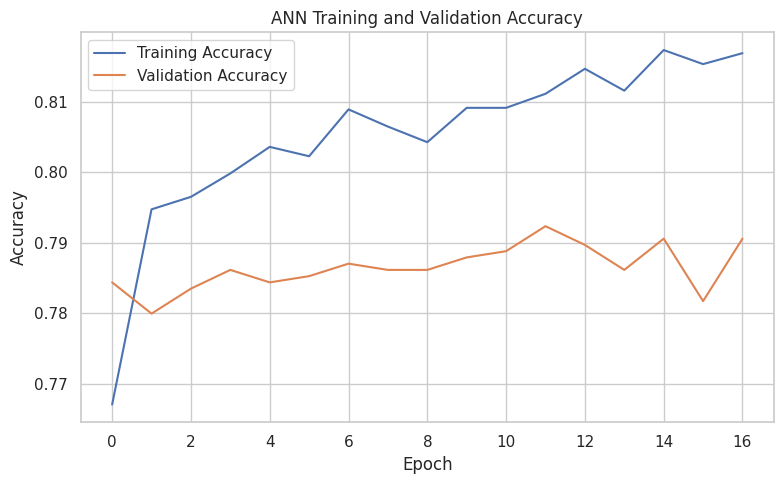

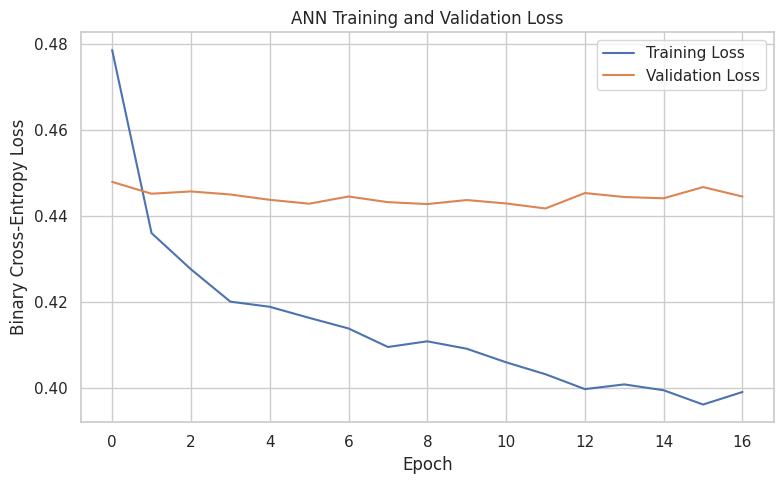

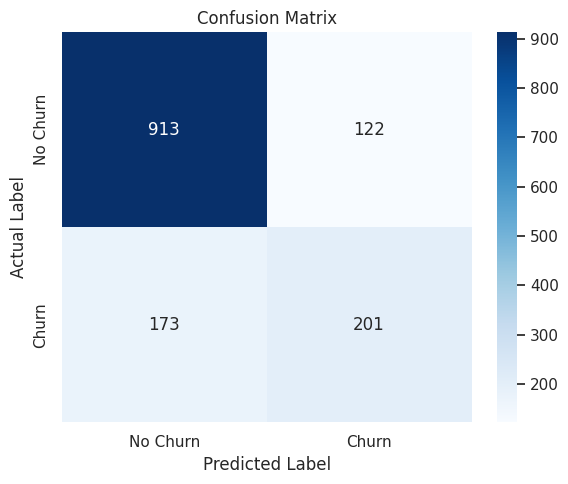

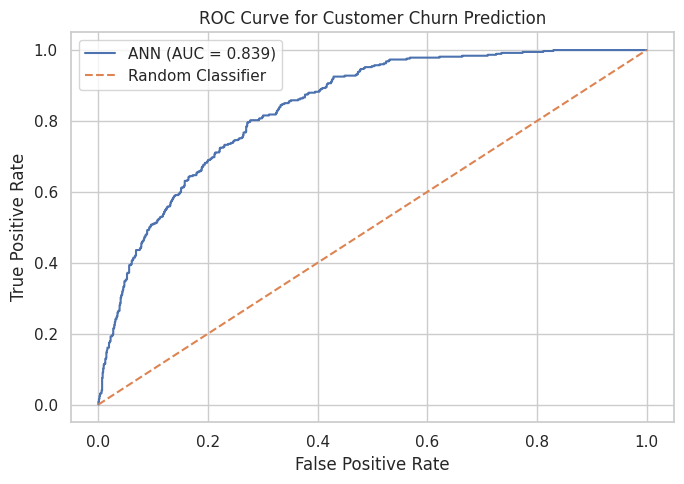

In [10]:

# CELL 7: MODEL EVALUATION VISUALIZATIONS

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

sns.set_theme(style="whitegrid")

# 1. Training and Validation Accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# 2. Training and Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.tight_layout()
plt.show()

# 3. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# 4. ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ANN (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curve for Customer Churn Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()


In [11]:

# CELL 8: SAVE MODEL AND PROJECT OUTPUTS

import os
import json
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Create an output folder
os.makedirs("churn_project", exist_ok=True)

# 1. Save the trained ANN model
model.save("churn_project/customer_churn_ann.keras")

# 2. Export the cleaned dataset
df_clean.to_csv(
    "churn_project/cleaned_customer_churn.csv",
    index=False
)

# 3. Save evaluation metrics
metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(precision_score(y_test, y_pred, zero_division=0)),
    "recall": float(recall_score(y_test, y_pred, zero_division=0)),
    "f1_score": float(f1_score(y_test, y_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test, y_prob))
}

with open("churn_project/evaluation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# 4. Save training history
pd.DataFrame(history.history).to_csv(
    "churn_project/training_history.csv",
    index_label="epoch"
)

# 5. Save the feature scaler and column information
import joblib

joblib.dump(scaler, "churn_project/scaler.pkl")
joblib.dump(X.columns.tolist(), "churn_project/feature_columns.pkl")

# 6. Display saved files
print("Project files saved successfully!")

for root, dirs, files in os.walk("churn_project"):
    for file in files:
        print(os.path.join(root, file))

print("\nEvaluation metrics:")
print(json.dumps(metrics, indent=4))


Project files saved successfully!
churn_project/scaler.pkl
churn_project/cleaned_customer_churn.csv
churn_project/evaluation_metrics.json
churn_project/training_history.csv
churn_project/feature_columns.pkl
churn_project/customer_churn_ann.keras

Evaluation metrics:
{
    "accuracy": 0.7906316536550745,
    "precision": 0.6222910216718266,
    "recall": 0.5374331550802139,
    "f1_score": 0.5767575322812052,
    "roc_auc": 0.8386395928595417
}
